In [27]:
# Importing necessary libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Importing preprocessing and model classes from sklearn
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression, Lasso, Ridge

# Importing metrics for model evaluation
from sklearn.metrics import mean_squared_error, confusion_matrix, accuracy_score
# Importing train_test_split for splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split
# Importing RandomForestClassifier for classification tasks
from sklearn.ensemble import RandomForestClassifier

# Suppressing warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Defining a class to hold color codes for terminal output
class color:
   PURPLE = '\033[95m'      # Purple color code
   CYAN = '\033[96m'        # Cyan color code
   DARKCYAN = '\033[36m'    # Dark Cyan color code
   BLUE = '\033[94m'        # Blue color code
   GREEN = '\033[92m'       # Green color code
   YELLOW = '\033[93m'      # Yellow color code
   RED = '\033[91m'         # Red color code
   BOLD = '\033[1m'         # Bold text code
   UNDERLINE = '\033[4m'    # Underlined text code
   END = '\033[0m'          # Reset color code

In [28]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

df.head()


Saving التعداد_السكاني_للدول_العربية.csv to التعداد_السكاني_للدول_العربية (2).csv


,الدولة,العدد السكاني,نسبة النمو السنوي (%),معدل الخصوبة,متوسط العمر,معدل الوفيات,المنطقة,عدد المدن,معدل الأمية (%),نسبة الحضر (%)
0,مصر,58072640,2.35,5.69,77.1,10.97,الشرق الأوسط,8,25.34,33.79
1,السعودية,58368540,1.41,4.86,55.9,14.55,الشرق الأوسط,7,13.82,61.94
2,العراق,85682344,2.49,4.25,26.2,1.66,الشرق الأوسط,2,13.80,83.47
3,اليمن,33526445,2.23,4.59,55.5,9.97,الشرق الأوسط,8,30.47,50.90
4,سوريا,82521285,0.65,5.71,67.8,2.86,الشرق الأوسط,10,26.38,55.62


In [29]:
print(df[['العدد السكاني', 'نسبة النمو السنوي (%)', 'معدل الخصوبة', 'متوسط العمر', 'معدل الوفيات', 'المنطقة', 'عدد المدن', 'معدل الأمية (%)', 'نسبة الحضر (%)', 'العدد السكاني']].head())

   العدد السكاني  نسبة النمو السنوي (%)  معدل الخصوبة  متوسط العمر  \
0       58072640                   2.35          5.69         77.1   
1       58368540                   1.41          4.86         55.9   
2       85682344                   2.49          4.25         26.2   
3       33526445                   2.23          4.59         55.5   
4       82521285                   0.65          5.71         67.8   

   معدل الوفيات       المنطقة  عدد المدن  معدل الأمية (%)  نسبة الحضر (%)  \
0         10.97  الشرق الأوسط          8            25.34           33.79   
1         14.55  الشرق الأوسط          7            13.82           61.94   
2          1.66  الشرق الأوسط          2            13.80           83.47   
3          9.97  الشرق الأوسط          8            30.47           50.90   
4          2.86  الشرق الأوسط         10            26.38           55.62   

   العدد السكاني  
0       58072640  
1       58368540  
2       85682344  
3       33526445  
4       82521285  


In [30]:
df.head()


,الدولة,العدد السكاني,نسبة النمو السنوي (%),معدل الخصوبة,متوسط العمر,معدل الوفيات,المنطقة,عدد المدن,معدل الأمية (%),نسبة الحضر (%)
0,مصر,58072640,2.35,5.69,77.1,10.97,الشرق الأوسط,8,25.34,33.79
1,السعودية,58368540,1.41,4.86,55.9,14.55,الشرق الأوسط,7,13.82,61.94
2,العراق,85682344,2.49,4.25,26.2,1.66,الشرق الأوسط,2,13.80,83.47
3,اليمن,33526445,2.23,4.59,55.5,9.97,الشرق الأوسط,8,30.47,50.90
4,سوريا,82521285,0.65,5.71,67.8,2.86,الشرق الأوسط,10,26.38,55.62


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   الدولة                 300 non-null    object 
 1   العدد السكاني          300 non-null    int64  
 2   نسبة النمو السنوي (%)  300 non-null    float64
 3   معدل الخصوبة           300 non-null    float64
 4   متوسط العمر            300 non-null    float64
 5   معدل الوفيات           300 non-null    float64
 6   المنطقة                300 non-null    object 
 7   عدد المدن              300 non-null    int64  
 8   معدل الأمية (%)        300 non-null    float64
 9   نسبة الحضر (%)         300 non-null    float64
dtypes: float64(6), int64(2), object(2)
memory usage: 23.6+ KB


In [32]:
df.sample(20)

,الدولة,العدد السكاني,نسبة النمو السنوي (%),معدل الخصوبة,متوسط العمر,معدل الوفيات,المنطقة,عدد المدن,معدل الأمية (%),نسبة الحضر (%)
33,موريتانيا,79624233,2.40,2.57,73.9,12.65,الشرق الأوسط,2,22.26,61.82
50,الجزائر,88956761,0.91,3.22,35.7,5.29,الشرق الأوسط,33,20.58,82.15
120,فلسطين,74251753,2.02,4.30,51.0,5.63,الشرق الأوسط,20,23.05,88.02
283,ليبيا,42899996,2.40,3.83,27.9,14.69,الشرق الأوسط,9,32.67,65.02
7,تونس,86689643,0.54,5.12,66.3,1.32,الشرق الأوسط,25,26.56,82.24
27,لبنان,37249357,2.31,2.11,47.8,1.16,الشرق الأوسط,19,37.77,63.24
109,سوريا,74679859,2.44,2.59,68.9,10.75,الشرق الأوسط,33,31.73,82.02
154,تونس,4030121,1.45,5.82,46.5,5.94,الشرق الأوسط,21,30.29,87.89
231,مصر,53726377,1.36,5.10,69.5,13.51,الشرق الأوسط,6,38.25,61.11
104,الإمارات,86741630,3.06,4.54,52.1,9.44,الشرق الأوسط,5,37.81,80.98


In [33]:
df.shape

(300, 10)

In [34]:
df.describe()

,العدد السكاني,نسبة النمو السنوي (%),معدل الخصوبة,متوسط العمر,معدل الوفيات,عدد المدن,معدل الأمية (%),نسبة الحضر (%)
count,3.000000e+02,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,5.040965e+07,1.926867,3.970133,51.728000,8.299800,24.340000,24.882000,61.012800
std,2.958710e+07,0.835633,1.140218,16.818222,4.093317,14.821493,8.409359,18.012294
min,1.162624e+06,0.500000,2.020000,20.700000,1.000000,1.000000,10.030000,30.150000
25%,2.466570e+07,1.237500,2.997500,38.400000,4.455000,10.750000,17.632500,43.960000
50%,5.081737e+07,1.900000,4.105000,51.800000,8.705000,25.000000,24.825000,62.040000
75%,7.713115e+07,2.562500,4.860000,67.100000,11.787500,38.000000,32.027500,76.632500
max,9.932739e+07,3.500000,5.970000,79.600000,14.940000,50.000000,39.900000,89.970000


In [35]:
# Check for missing values
print(df.isnull().sum())

الدولة                   0
العدد السكاني            0
نسبة النمو السنوي (%)    0
معدل الخصوبة             0
متوسط العمر              0
معدل الوفيات             0
المنطقة                  0
عدد المدن                0
معدل الأمية (%)          0
نسبة الحضر (%)           0
dtype: int64


In [36]:
df.duplicated().sum()

np.int64(0)

In [37]:
print(df.dtypes)

الدولة                    object
العدد السكاني              int64
نسبة النمو السنوي (%)    float64
معدل الخصوبة             float64
متوسط العمر              float64
معدل الوفيات             float64
المنطقة                   object
عدد المدن                  int64
معدل الأمية (%)          float64
نسبة الحضر (%)           float64
dtype: object


In [38]:
# Encoder to transform categorical variables into numerical values
labelencoder = LabelEncoder()

# First, let's check the actual column names in the DataFrame
# Uncomment the line below to see the actual column names
# print(df.columns.tolist())

# Define a function to process columns that contain categorical data
def process_column(column):
    # Replace specific string values with a single value to reduce complexity
    column = column.replace(["No العدد السكاني ", "No متوسط العمر"], "No")
    # Convert "Yes" to 1
    column = column.replace("Yes", "1")
    # Convert "No" to 0
    column = column.replace("No", "0")
    # Convert the column to a numeric type, coercing any errors to NaN
    return pd.to_numeric(column, errors='coerce')

# Make sure the column names match exactly with what's in the DataFrame
# Check for extra spaces or different spellings
columns = ["الدولة",
           "العدد السكاني",
           "معدل الخصوبة",
           "متوسط العمر",  # Fixed: Corrected the reversed Arabic text
           "معدل الوفيات",
           "عدد المدن",
           "نسبة الحضر (%)"
]  # Fixed: Added commas between column names

# Apply the process_column function to each column in the columns list
for column in columns:
    if column in df.columns:  # Check if the column exists before processing
        df[column] = process_column(df[column])
    else:
        print(f"Warning: Column '{column}' not found in DataFrame")

# List of additional categorical columns that need to be converted to numerical format
categorical_columns = ["الدولة", "العدد السكاني", "متوسط العمر"]  # Fixed: Added closing quote and comma

# Transform the categorical columns into numerical values using LabelEncoder
for column in categorical_columns:
    if column in df.columns:  # Check if the column exists before processing
        df[column] = labelencoder.fit_transform(df[column])
    else:
        print(f"Warning: Column '{column}' not found in DataFrame")

# Drop any rows with NaN values that may have resulted from processing
df = df.dropna()

In [39]:
labelencoder = LabelEncoder()
columns =  ["الدولة", "العدد السكاني", "متوسط العمر"]

for column in columns:
    df[column] = labelencoder.fit_transform(df[column])

In [40]:
import pandas as pd

# Step 1: Convert the 'TotalCharges' column to string
df['العدد السكاني'] = df['العدد السكاني'].astype(str)

# Step 2: Remove unwanted characters like '$' or ','
df['العدد السكاني'] = df['العدد السكاني'].str.replace('[\$,]', '', regex=True)

# Step 3: Convert the cleaned 'TotalCharges' column to numeric values
df['Tالعدد السكاني'] = pd.to_numeric(df['العدد السكاني'], errors='coerce')


In [41]:

print(df.select_dtypes(include=['number']).median())

الدولة                     0.000
نسبة النمو السنوي (%)      1.900
معدل الخصوبة               4.105
متوسط العمر              125.500
معدل الوفيات               8.705
عدد المدن                 25.000
معدل الأمية (%)           24.825
نسبة الحضر (%)            62.040
Tالعدد السكاني           149.500
dtype: float64


In [42]:
print(df.select_dtypes(include=['number']).mode())

     الدولة  نسبة النمو السنوي (%)  معدل الخصوبة  متوسط العمر  معدل الوفيات  \
0       0.0                   2.54          4.66         19.0         11.13   
1       NaN                   3.26           NaN          NaN         12.29   
2       NaN                    NaN           NaN          NaN           NaN   
3       NaN                    NaN           NaN          NaN           NaN   
4       NaN                    NaN           NaN          NaN           NaN   
..      ...                    ...           ...          ...           ...   
295     NaN                    NaN           NaN          NaN           NaN   
296     NaN                    NaN           NaN          NaN           NaN   
297     NaN                    NaN           NaN          NaN           NaN   
298     NaN                    NaN           NaN          NaN           NaN   
299     NaN                    NaN           NaN          NaN           NaN   

     عدد المدن  معدل الأمية (%)  نسبة الحضر (%)  Tا

In [43]:
print(color.BOLD + 'Mean' + color.END)
print(df.select_dtypes(include=['number']).mean())

Mean
الدولة                     0.000000
نسبة النمو السنوي (%)      1.926867
معدل الخصوبة               3.970133
متوسط العمر              124.860000
معدل الوفيات               8.299800
عدد المدن                 24.340000
معدل الأمية (%)           24.882000
نسبة الحضر (%)            61.012800
Tالعدد السكاني           149.500000
dtype: float64


In [44]:
print(df.head())

   الدولة العدد السكاني  نسبة النمو السنوي (%)  معدل الخصوبة  متوسط العمر  \
0       0           173                   2.35          5.69          237   
1       0           175                   1.41          4.86          140   
2       0           248                   2.49          4.25           19   
3       0           101                   2.23          4.59          138   
4       0           238                   0.65          5.71          190   

   معدل الوفيات       المنطقة  عدد المدن  معدل الأمية (%)  نسبة الحضر (%)  \
0         10.97  الشرق الأوسط          8            25.34           33.79   
1         14.55  الشرق الأوسط          7            13.82           61.94   
2          1.66  الشرق الأوسط          2            13.80           83.47   
3          9.97  الشرق الأوسط          8            30.47           50.90   
4          2.86  الشرق الأوسط         10            26.38           55.62   

   Tالعدد السكاني  
0             173  
1             175  
2             

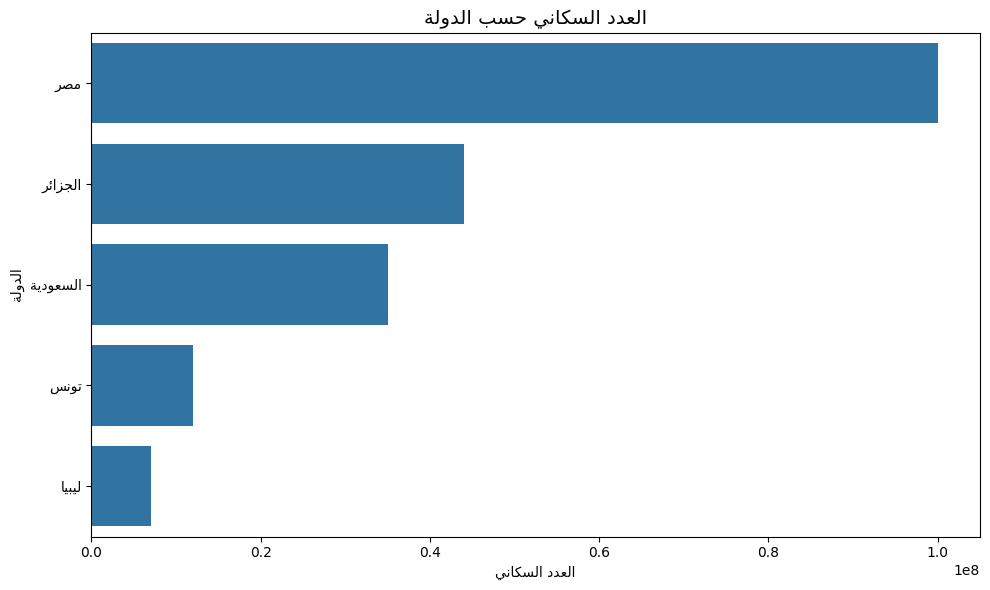

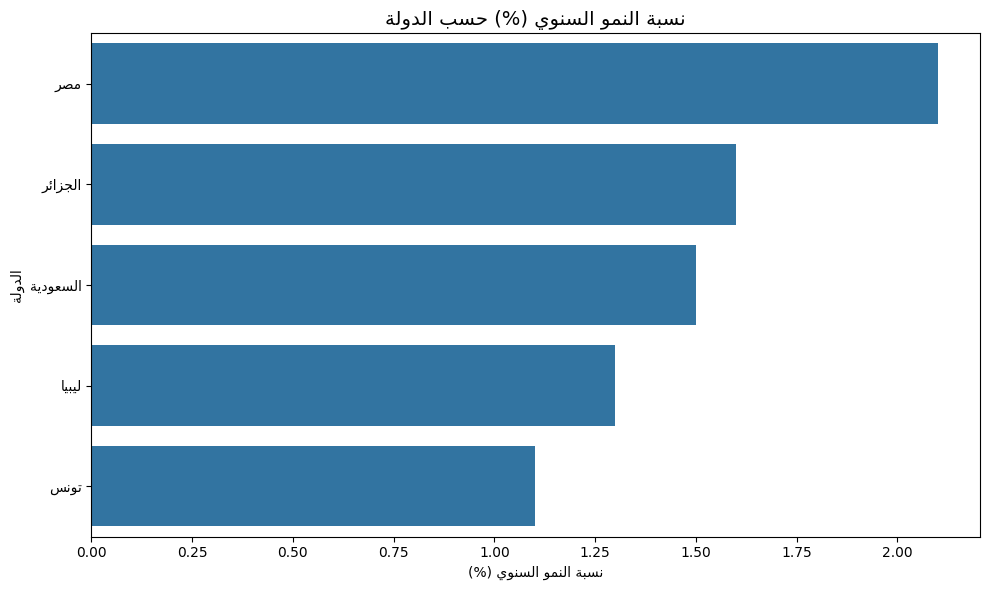

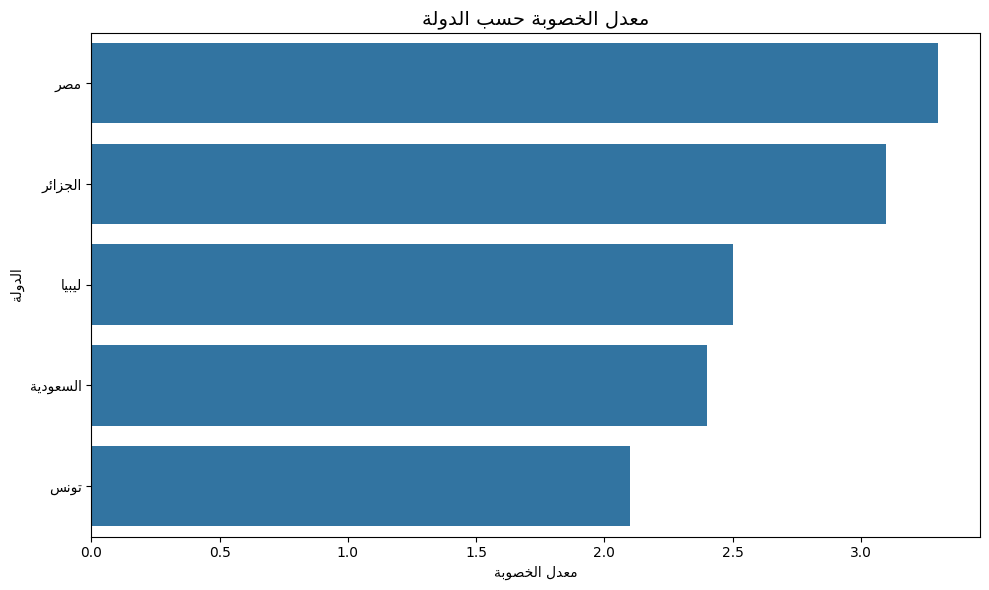

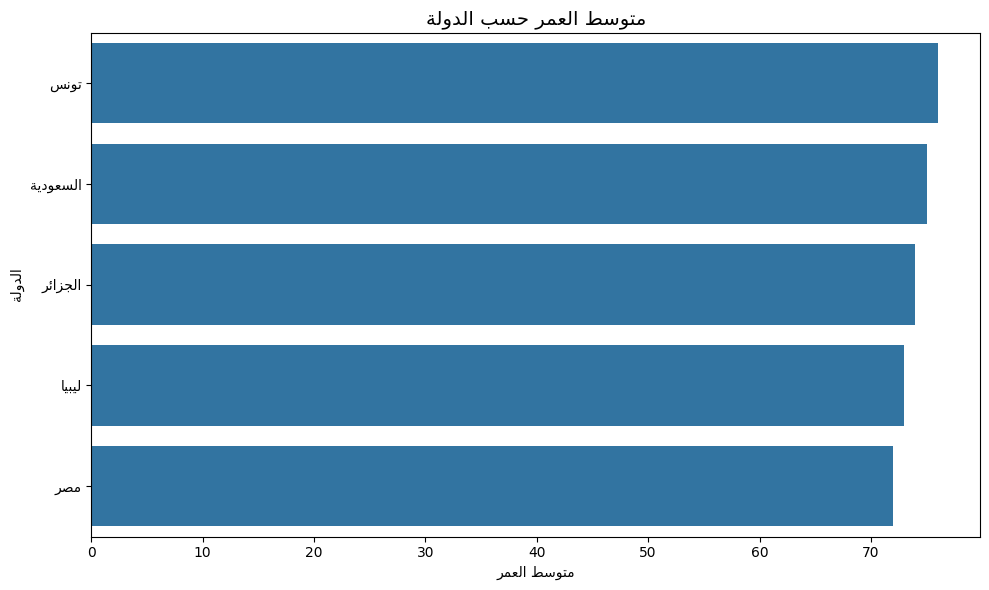

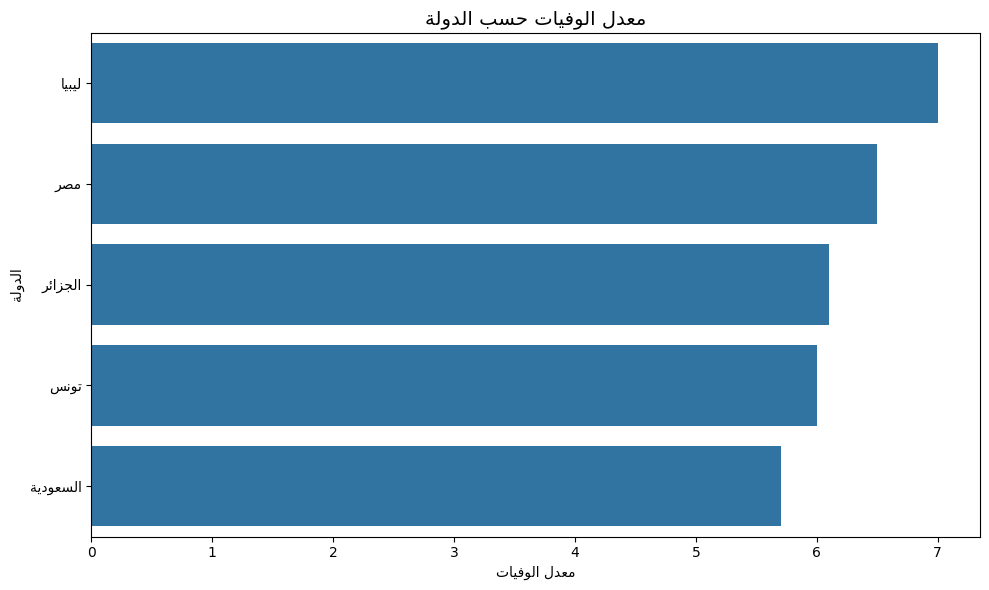

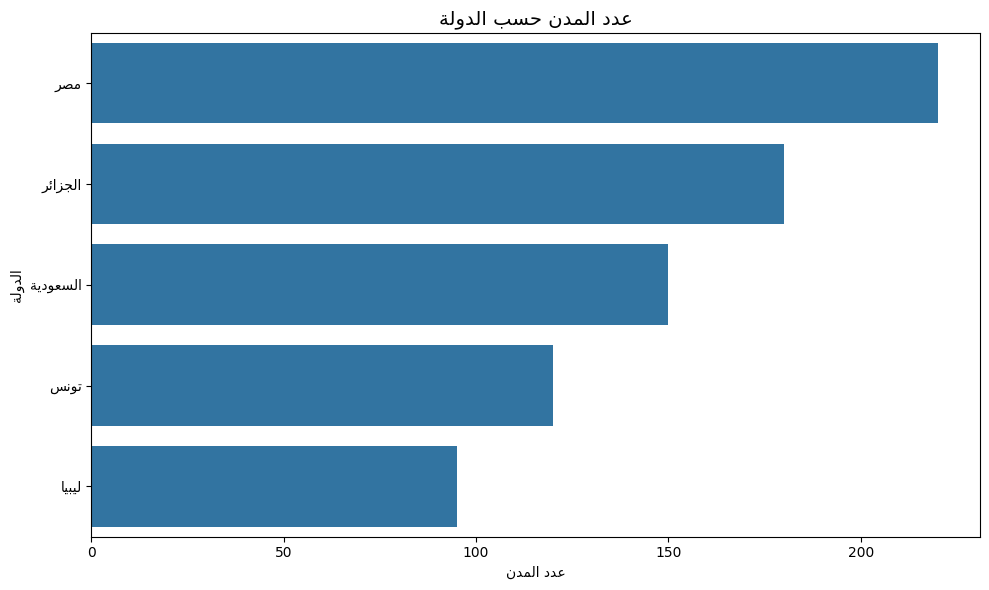

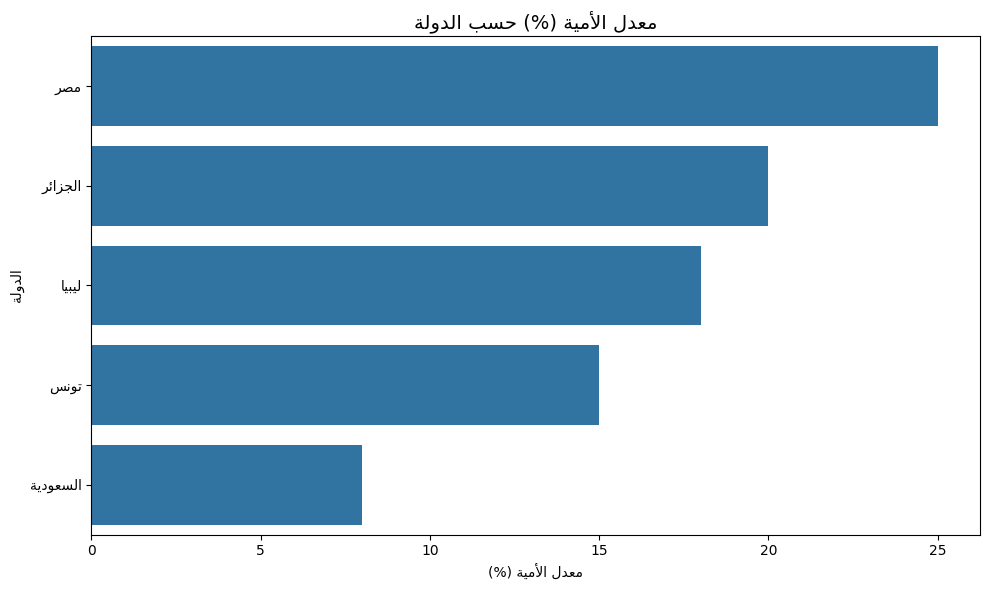

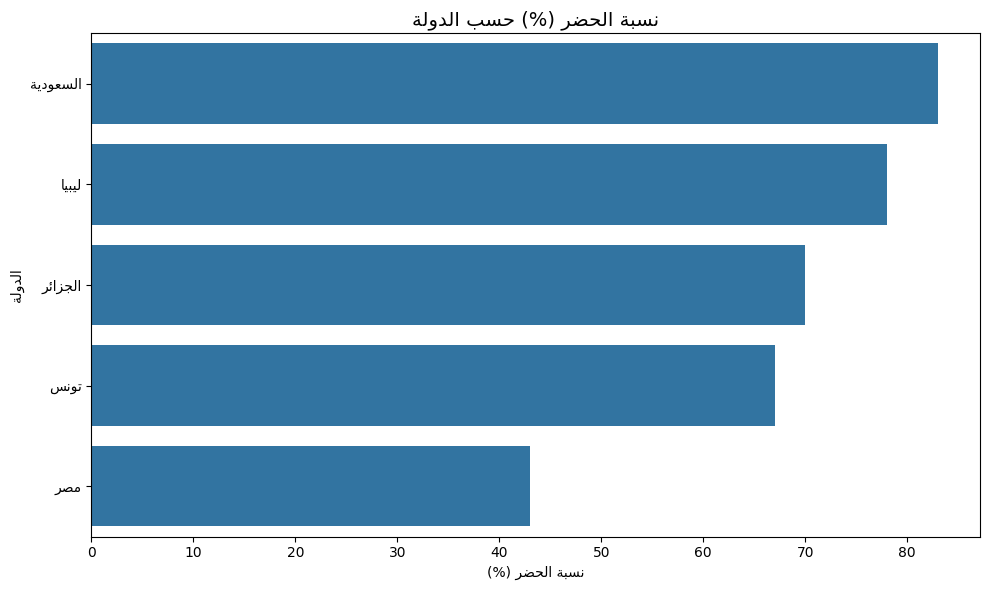

In [62]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display

# البيانات
data = {
    'الدولة': ['مصر', 'السعودية', 'الجزائر', 'تونس', 'ليبيا'],
    'العدد السكاني': [100_000_000, 35_000_000, 44_000_000, 12_000_000, 7_000_000],
    'نسبة النمو السنوي (%)': [2.1, 1.5, 1.6, 1.1, 1.3],
    'معدل الخصوبة': [3.3, 2.4, 3.1, 2.1, 2.5],
    'متوسط العمر': [72, 75, 74, 76, 73],
    'معدل الوفيات': [6.5, 5.7, 6.1, 6.0, 7.0],
    'عدد المدن': [220, 150, 180, 120, 95],
    'معدل الأمية (%)': [25, 8, 20, 15, 18],
    'نسبة الحضر (%)': [43, 83, 70, 67, 78]
}

df = pd.DataFrame(data)

# إعداد الخط المناسب لـ Google Colab
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# إصلاح عرض النصوص العربية
def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))

# تعديل أسماء الدول
df['الدولة_معدلة'] = df['الدولة'].apply(ar)

# الأعمدة التي سنرسمها
اعمدة_للرسم = [
    col for col in df.columns
    if col not in ['الدولة', 'الدولة_معدلة']
]

# رسم كل عمود على حدة
for العمود in اعمدة_للرسم:
    df_sorted = df.sort_values(by=العمود, ascending=False)

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(
        x=العمود,
        y='الدولة_معدلة',
        data=df_sorted
    )

    plt.title(ar(f'{العمود} حسب الدولة'), fontsize=14)
    plt.xlabel(ar(العمود))
    plt.ylabel(ar('الدولة'))

    plt.tight_layout()
    plt.show()


In [46]:
import arabic_reshaper
from bidi.algorithm import get_display
print("تمام، المكتبات شغالة ✅")


تمام، المكتبات شغالة ✅


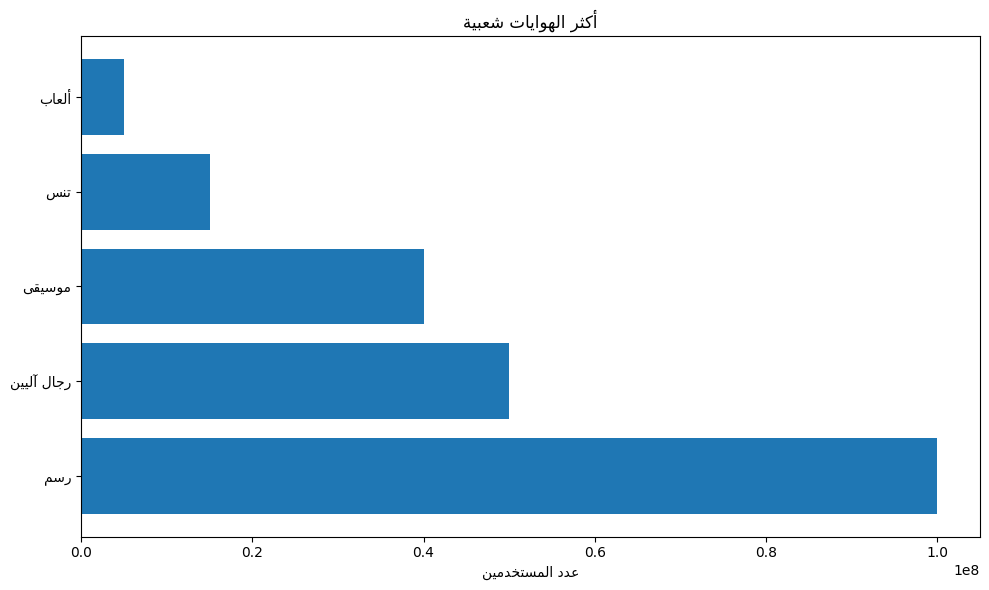

In [63]:

import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

# البيانات (مثال)
labels = ['رسم', 'رجال آليين', 'موسيقى', 'تنس', 'ألعاب']
values = [100_000_000, 50_000_000, 40_000_000, 15_000_000, 5_000_000]

# إعداد الخط قبل الرسم
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# دالة إصلاح عرض النص العربي
def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))

# تجهيز أسماء الهوايات
fixed_labels = [ar(label) for label in labels]

# الرسم البياني
plt.figure(figsize=(10, 6))
plt.barh(fixed_labels, values)

plt.xlabel(ar('عدد المستخدمين'))
plt.title(ar('أكثر الهوايات شعبية'))

plt.tight_layout()
plt.show()


In [48]:

%pip install arabic-reshaper python-bidi


In [56]:

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False


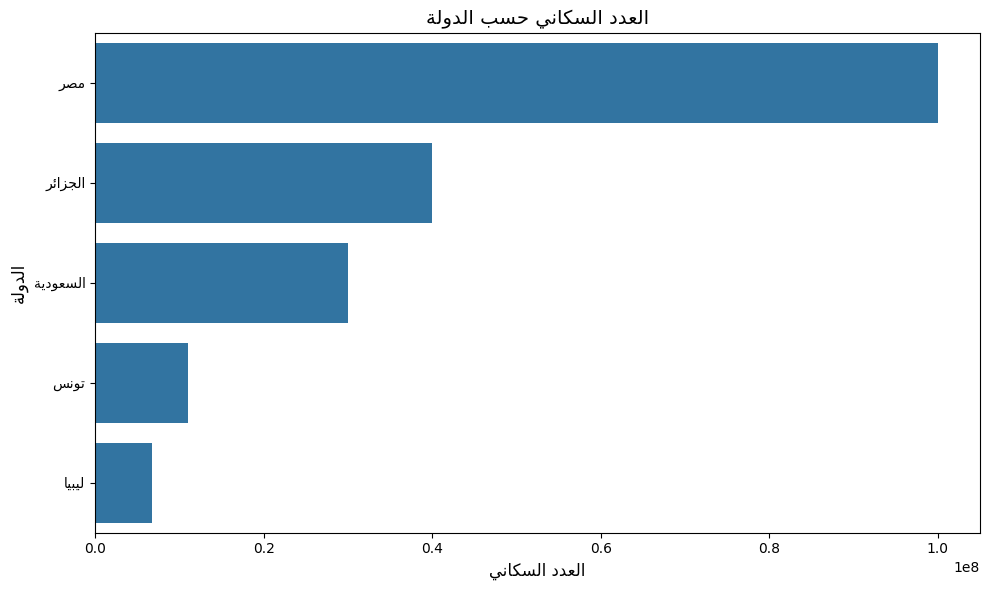

In [64]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arabic_reshaper
from bidi.algorithm import get_display

# إعداد دعم الخط العربي
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# دالة لتصحيح عرض العربية
def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))

# بيانات توضيحية
data = {
    'الدولة': ['مصر', 'السعودية', 'الجزائر', 'تونس', 'ليبيا'],
    'العدد السكاني': [100000000, 30000000, 40000000, 11000000, 6800000]
}
df = pd.DataFrame(data)

# تصحيح أسماء الدول
df['الدولة_مشكلة'] = df['الدولة'].apply(ar)

# ترتيب البيانات
df_sorted = df.sort_values(
    by='العدد السكاني',
    ascending=False
)

# رسم بياني أفقي
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x='العدد السكاني',
    y='الدولة_مشكلة',
    data=df_sorted
)

# العنوان والمحاور بالعربية
plt.title(ar('العدد السكاني حسب الدولة'), fontsize=14)
plt.xlabel(ar('العدد السكاني'), fontsize=12)
plt.ylabel(ar('الدولة'), fontsize=12)

plt.tight_layout()
plt.show()


In [51]:

df = pd.read_csv('/content/التعداد_السكاني_للدول_العربية.csv')


أسماء الأعمدة:
['الدولة', 'العدد السكاني', 'نسبة النمو السنوي (%)', 'معدل الخصوبة', 'متوسط العمر', 'معدل الوفيات', 'المنطقة', 'عدد المدن', 'معدل الأمية (%)', 'نسبة الحضر (%)']


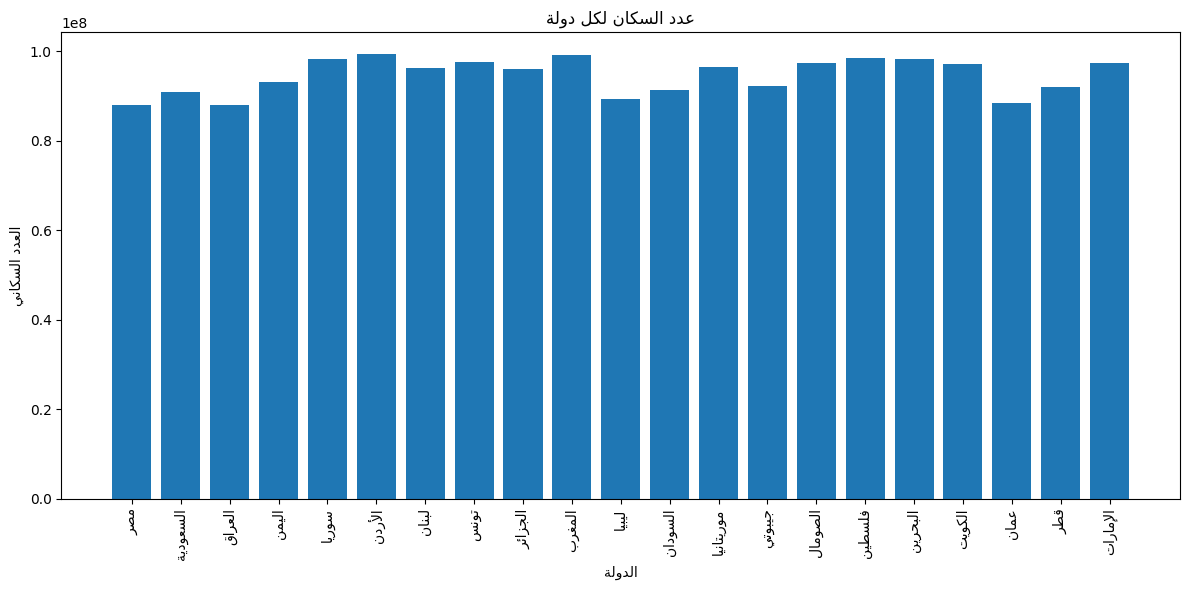

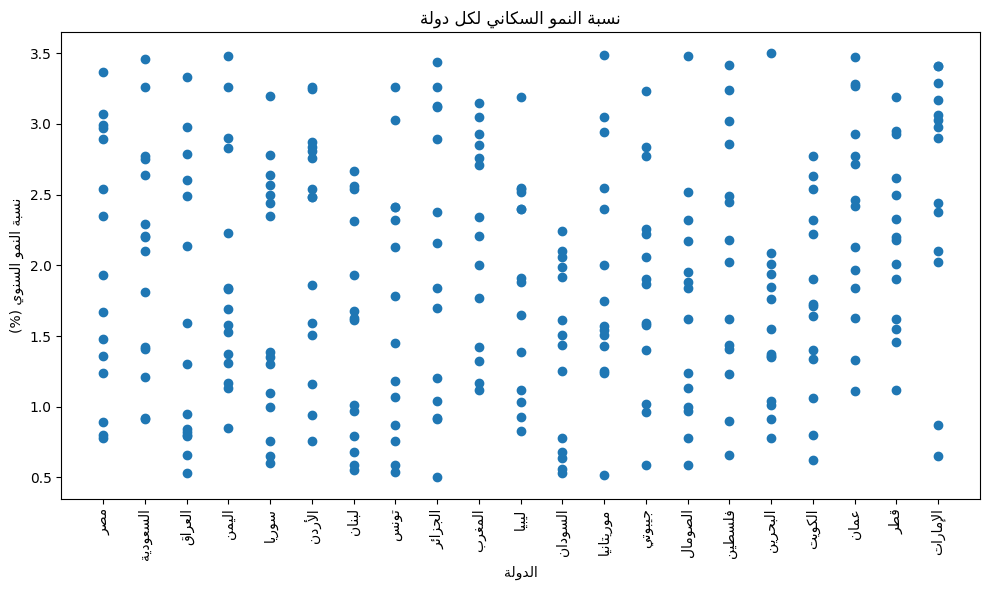

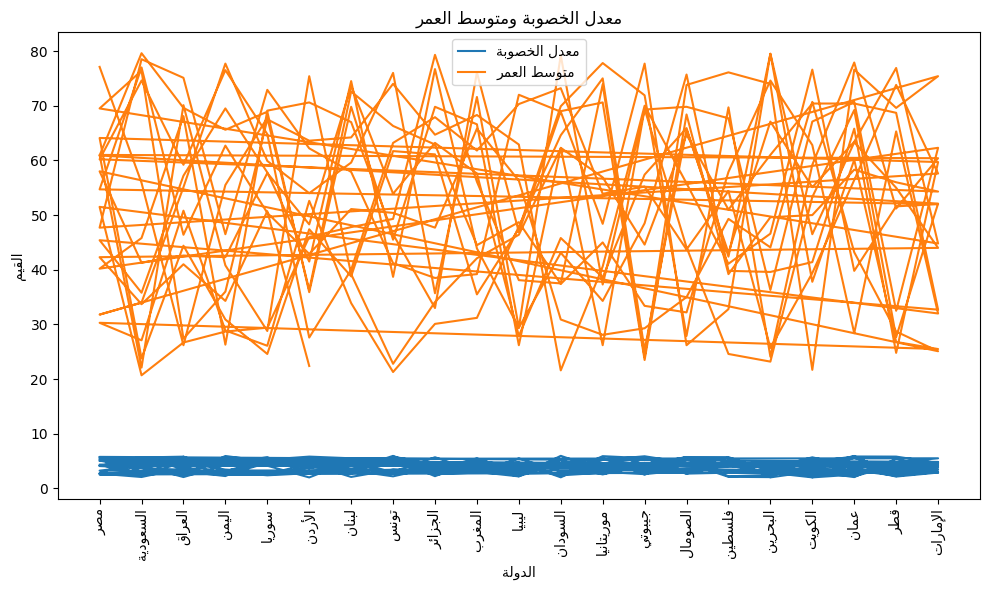

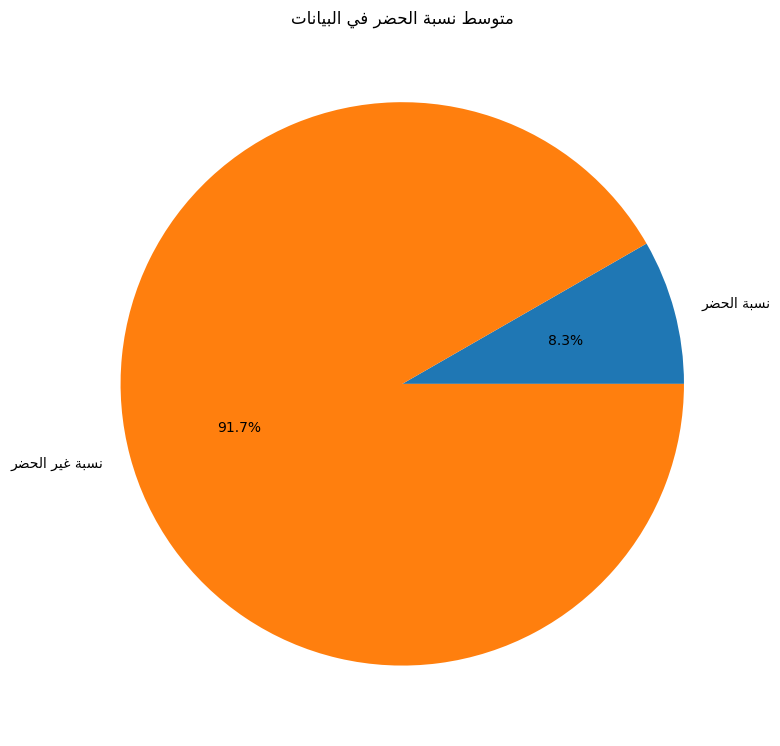

In [61]:

import pandas as pd
import matplotlib.pyplot as plt
import arabic_reshaper
from bidi.algorithm import get_display

# إصلاح عرض النصوص العربية
def ar(text):
    return get_display(arabic_reshaper.reshape(str(text)))

# إعداد الخط
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# قراءة البيانات
df = pd.read_csv('/content/التعداد_السكاني_للدول_العربية.csv')

print("أسماء الأعمدة:")
print(df.columns.tolist())

# تحديد الأعمدة
country_column = df.columns[0]
population_column = df.columns[1]
growth_rate_column = df.columns[2]
fertility_column = df.columns[3]
life_expectancy_column = df.columns[4]
urban_percentage_column = df.columns[5]

# أسماء الدول بالعربية
countries = [ar(x) for x in df[country_column]]

# 1. عدد السكان لكل دولة
plt.figure(figsize=(12, 6))
plt.bar(countries, df[population_column])
plt.xlabel(ar('الدولة'))
plt.ylabel(ar('العدد السكاني'))
plt.title(ar('عدد السكان لكل دولة'))
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 2. نسبة النمو السكاني
plt.figure(figsize=(10, 6))
plt.scatter(countries, df[growth_rate_column])
plt.xlabel(ar('الدولة'))
plt.ylabel(ar('نسبة النمو السنوي (%)'))
plt.title(ar('نسبة النمو السكاني لكل دولة'))
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 3. معدل الخصوبة ومتوسط العمر
plt.figure(figsize=(10, 6))
plt.plot(countries, df[fertility_column],
         label=ar('معدل الخصوبة'))
plt.plot(countries, df[life_expectancy_column],
         label=ar('متوسط العمر'))
plt.xlabel(ar('الدولة'))
plt.ylabel(ar('القيم'))
plt.title(ar('معدل الخصوبة ومتوسط العمر'))
plt.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 4. متوسط نسبة الحضر
avg_urban_percentage = df[urban_percentage_column].mean()

plt.figure(figsize=(8, 8))
plt.pie(
    [avg_urban_percentage, 100 - avg_urban_percentage],
    labels=[
        ar('نسبة الحضر'),
        ar('نسبة غير الحضر')
    ],
    autopct='%1.1f%%'
)
plt.title(ar('متوسط نسبة الحضر في البيانات'))
plt.tight_layout()
plt.show()
